# 02 — Target definition + numerical (sensor / phenotype) model

Inputs: the clean files saved by notebook 01 in `alprotein_outputs/`.

Plan:
1. **Target** = plant-height gain between the two days that were really measured (7 → 13 June). No interpolated values are used as targets.
2. **Numerical features** = the plant's own measurements on 7 June (allowed: they are known at the start of the interval) + environmental conditions of its sensor zone during 7 → 13 June.
3. **Models**: mean baseline, phenotype-only, sensor-only, phenotype + sensor (Ridge and Random Forest).
4. **Evaluation**: MAE, RMSE, R² from out-of-fold predictions, with two CV schemes.

In [2]:
# --- Setup -------------------------------------------------------------------
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    from google.colab import drive
    drive.mount('/content/drive')
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

# EDIT THIS if needed: same DATA_DIR as notebook 01
DATA_DIR = Path('/content/drive/MyDrive/25 tomato dataset') if IN_COLAB else Path(os.environ.get('DATA_DIR', 'data'))
OUT_DIR = DATA_DIR.parent / 'alprotein_outputs'
assert (OUT_DIR / 'growth_daily.parquet').exists(), f'Run notebook 01 first (nothing found in {OUT_DIR})'

SEED = 42
np.random.seed(SEED)
pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 40)

growth = pd.read_parquet(OUT_DIR / 'growth_daily.parquet')
zone_ts = pd.read_parquet(OUT_DIR / 'sensors_zone_30min.parquet')
plants = pd.read_csv(OUT_DIR / 'plant_map.csv')
print(growth.shape, zone_ts.shape, plants.shape)

Mounted at /content/drive
(780, 21) (6468, 8) (60, 8)


## 1. Target: height gain between the two measured days

- `t0` = 7 June, `t1` = 13 June (the only two real measurement days in June).
- `y = height(t1) − height(t0)` in the dataset's height unit (cm), over 6 days.
- Everything measured on `t0` can be used as a feature. Nothing measured on `t1` can.

t0 = 2025-06-07  t1 = 2025-06-13  interval = 6 days
count    60.00
mean     18.93
std      10.78
min     -13.00
25%      12.75
50%      21.00
75%      24.25
max      57.00
Name: y, dtype: float64


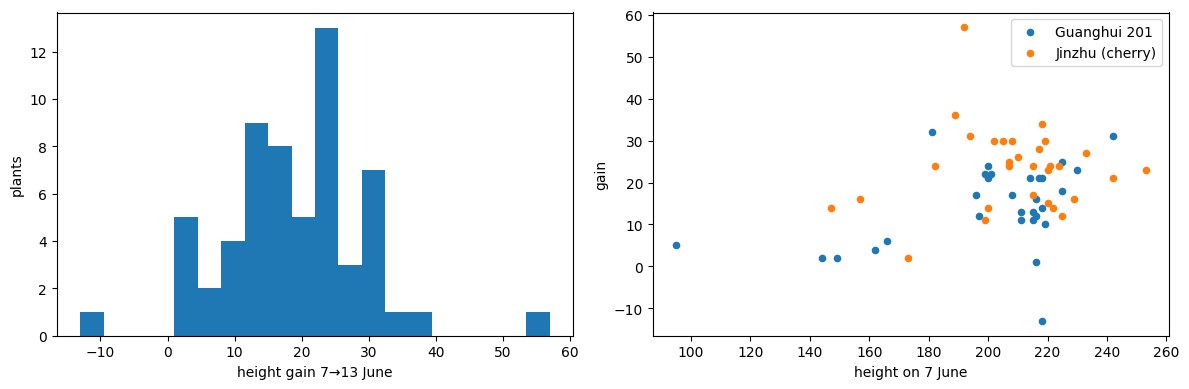

,plant,treatment,variety_name,Plant Height_t0,height_t1,y
2,L113,T1,Guanghui 201,218.0,205.0,-13.0
44,L613,T6,Guanghui 201,216.0,217.0,1.0
46,L622,T6,Jinzhu (cherry),173.0,175.0,2.0
54,L614,T6,Guanghui 201,144.0,146.0,2.0
50,L516,T5,Guanghui 201,149.0,151.0,2.0


In [3]:
measured_days = sorted(growth.loc[growth.is_measured, 'date'].unique())
assert len(measured_days) >= 2, 'Need two measured days'
T0, T1 = pd.Timestamp(measured_days[0]), pd.Timestamp(measured_days[1])
print('t0 =', T0.date(), ' t1 =', T1.date(), ' interval =', (T1 - T0).days, 'days')

PHENO = ['Plant Height', 'Stem Diameter', 'Leaf Width', 'Leaf Length', 'NDVI', 'RVI', 'LNC', 'LNA', 'LAI', 'LDW']
g0 = growth[growth.date == T0].set_index('plant')
g1 = growth[growth.date == T1].set_index('plant')

data = plants.set_index('plant').copy()
for c in PHENO:
    data[f'{c}_t0'] = g0[c]
data['y'] = g1['Plant Height'] - g0['Plant Height']
data['height_t1'] = g1['Plant Height']
data = data.reset_index()

print(data['y'].describe().round(2))
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(data['y'], bins=20); ax[0].set_xlabel('height gain 7→13 June'); ax[0].set_ylabel('plants')
for v, g in data.groupby('variety_name'):
    ax[1].scatter(g['Plant Height_t0'], g['y'], label=v, s=20)
ax[1].set_xlabel('height on 7 June'); ax[1].set_ylabel('gain'); ax[1].legend()
plt.tight_layout(); plt.show()

display(data.sort_values('y').head(5)[['plant', 'treatment', 'variety_name', 'Plant Height_t0', 'height_t1', 'y']])

**Note:** a negative gain (e.g. L113) is physically odd for plant height → probably pruning/topping, a broken stem, or a measuring error.
We keep it in the data (removing it would hide a real case) and look at it in the error analysis.

## 2. Sensor features for the interval 7 → 13 June

Each plant gets the conditions of **its** sensor zone (`plant_map.csv`). Where a zone has no data
(T3, T4 always; T2, T5 after 10 June) the gap is filled with the greenhouse mean, and we record how much was filled.

Features (all computed only over `[t0, t1)`):
- air temperature: mean, mean daily max, mean daily min, **growing degree-days** (base 10 °C)
- light: total (sum × 0.5 h; unit not documented) and mean daytime light
- relative humidity mean and **VPD** (vapour-pressure deficit, from temperature + RH)
- daytime CO₂ mean
- soil moisture change over the interval, soil temperature (relative to probe baseline)

In [4]:
AIR = ['air_temp', 'rh', 'light', 'co2']
SOIL = [c for c in ['soil_moisture_delta', 'soil_temp_delta'] if c in zone_ts.columns]
VARS = AIR + SOIL

win = zone_ts[(zone_ts.time >= T0) & (zone_ts.time < T1)]
gh = win[win.zone == 'GH_MEAN'].set_index('time')[VARS]
full_index = pd.date_range(T0, T1, freq='30min', inclusive='left')
gh = gh.reindex(full_index).interpolate(limit_direction='both')

def zone_window(zone):
    z = win[win.zone == zone].set_index('time')[VARS].reindex(full_index)
    filled = z.isna().mean().mean()            # share of values taken from greenhouse mean
    return z.fillna(gh), filled

def vpd_kpa(t, rh):
    es = 0.6108 * np.exp(17.27 * t / (t + 237.3))  # saturation vapour pressure (kPa)
    return es * (1 - rh / 100)

def sensor_features(z):
    day = z['light'] > 0.5
    daily = z['air_temp'].resample('D')
    f = {
        'temp_mean': z['air_temp'].mean(),
        'temp_max_daily': daily.max().mean(),
        'temp_min_daily': daily.min().mean(),
        'gdd_base10': (z['air_temp'] - 10).clip(lower=0).sum() / 48,   # degree-days
        'light_sum': z['light'].sum() * 0.5,
        'light_day_mean': z.loc[day, 'light'].mean(),
        'rh_mean': z['rh'].mean(),
        'vpd_mean': vpd_kpa(z['air_temp'], z['rh']).mean(),
        'vpd_day_mean': vpd_kpa(z.loc[day, 'air_temp'], z.loc[day, 'rh']).mean(),
        'co2_day_mean': z.loc[day, 'co2'].mean(),
    }
    if 'soil_moisture_delta' in z:
        sm = z['soil_moisture_delta'].dropna()
        f['soil_moisture_change'] = sm.iloc[-48:].mean() - sm.iloc[:48].mean()
    if 'soil_temp_delta' in z:
        f['soil_temp_rel_mean'] = z['soil_temp_delta'].mean()
    return f

rows = []
for zone in sorted(data['sensor_zone'].unique()):
    z, filled = zone_window(zone)
    rows.append({'sensor_zone': zone, 'filled_from_gh': round(filled, 2), **sensor_features(z)})
zone_feats = pd.DataFrame(rows)
display(zone_feats.round(2))

SENSOR_FEATS = [c for c in zone_feats.columns if c not in ('sensor_zone', 'filled_from_gh')]
data = data.merge(zone_feats, on='sensor_zone', how='left')

,sensor_zone,filled_from_gh,temp_mean,temp_max_daily,temp_min_daily,gdd_base10,light_sum,light_day_mean,rh_mean,vpd_mean,vpd_day_mean,co2_day_mean,soil_moisture_change,soil_temp_rel_mean
0,CK2,0.00,23.16,30.20,17.08,78.96,288.12,3.94,73.08,0.84,1.11,497.45,-0.38,1.71
1,GH_MEAN,0.00,23.90,32.30,17.48,83.39,609.76,7.03,68.43,1.05,1.38,511.24,0.26,2.06
2,T1,0.00,24.77,33.09,17.92,88.64,761.67,8.78,66.97,1.19,1.59,543.72,-4.10,2.95
3,T2,0.49,23.84,33.25,16.94,83.04,540.06,6.55,66.27,1.15,1.54,503.53,1.90,0.85
4,T5,0.51,23.82,33.72,16.82,82.94,547.44,6.73,66.33,1.15,1.54,521.15,4.43,0.85
5,T6,0.00,23.90,33.03,17.67,83.37,911.54,10.29,69.50,1.02,1.34,490.64,-0.54,3.92


**Important limitation:** there are only a handful of distinct sensor zones, so every sensor feature takes only a few
different values across the 60 plants. Sensor features can therefore only explain differences **between zones**,
never between plants in the same zone.

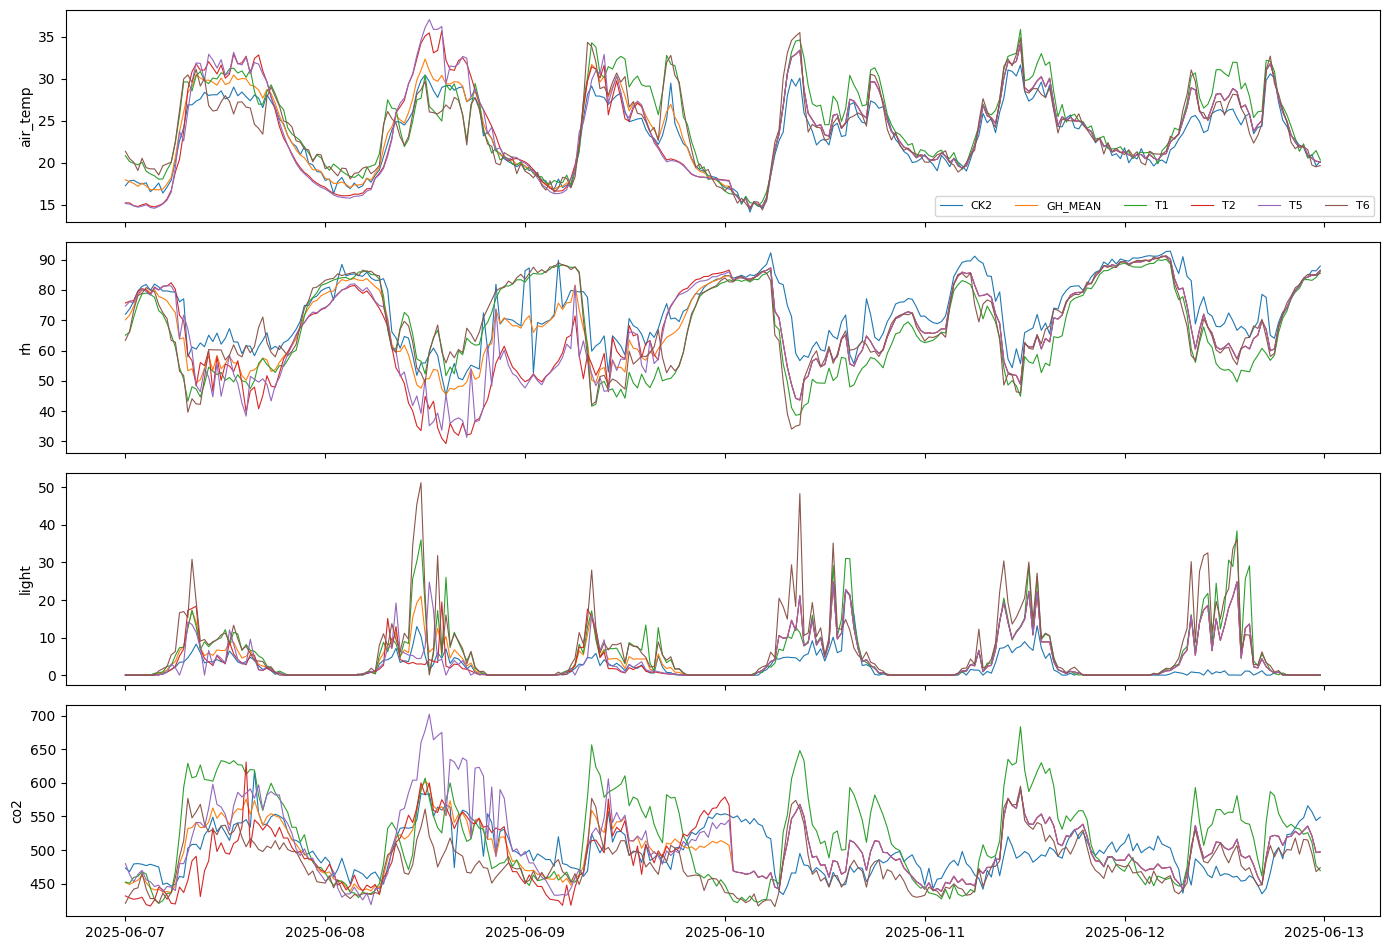

In [5]:
# Plot the environmental history of each zone during the interval
fig, axes = plt.subplots(len(AIR), 1, figsize=(14, 2.4 * len(AIR)), sharex=True)
for zone in sorted(data['sensor_zone'].unique()):
    z, _ = zone_window(zone)
    for ax, v in zip(axes, AIR):
        ax.plot(z.index, z[v], lw=.8, label=zone)
for ax, v in zip(axes, AIR):
    ax.set_ylabel(v)
axes[0].legend(ncol=8, fontsize=8)
plt.tight_layout(); plt.show()

## 3. Associations (descriptive, not causal)

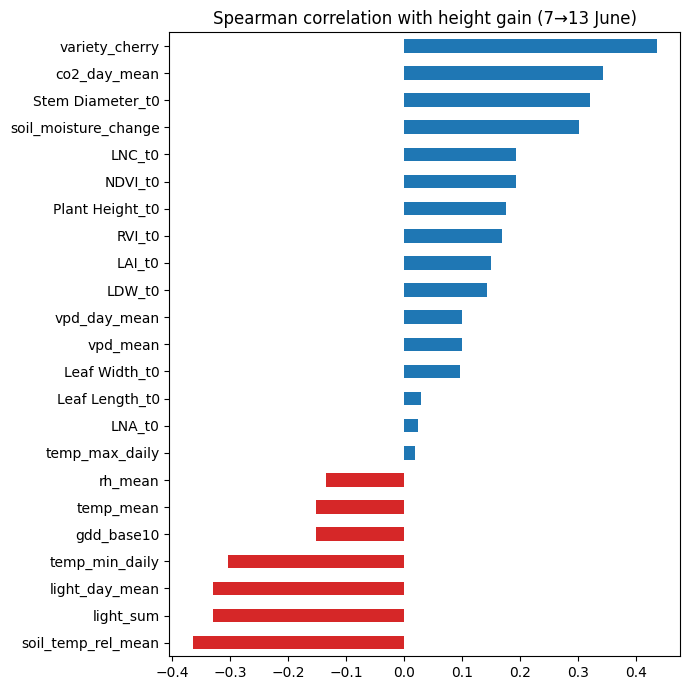

In [6]:
data['variety_cherry'] = (data['variety'] == 2).astype(int)
PHENO_FEATS = [f'{c}_t0' for c in PHENO] + ['variety_cherry']

corr = (data[PHENO_FEATS + SENSOR_FEATS + ['y']].corr(method='spearman')['y']
        .drop('y').sort_values())
fig, ax = plt.subplots(figsize=(7, 7))
corr.plot.barh(ax=ax, color=['C3' if v < 0 else 'C0' for v in corr])
ax.set_title('Spearman correlation with height gain (7→13 June)')
plt.tight_layout(); plt.show()

Read this carefully:
- Sensor features are confounded with **treatment** and **camera position** (each zone = one or two treatments), so a correlation here
  cannot separate "warmer zone" from "different fertiliser" from "different spot in the greenhouse".
- With ~6 zones, any sensor correlation rests on ~6 independent points.

## 4. Models

Cross-validation (each plant appears once, so there is no temporal leakage within a plant):
- **Random 5-fold, repeated 10×** — optimistic: neighbours from the same camera/zone can be in train and test.
- **Leave-one-camera-out (5 folds)** — stricter: the model must predict a whole camera group (12 plants, 1–2 zones) it never saw.
  This is the same grouping we will use for the image models, so all comparisons are fair.

Only `y` (gain) is predicted. Features are standardised inside each fold (Pipeline), so no test information leaks into scaling.

In [7]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import RidgeCV
from sklearn.ensemble import RandomForestRegressor
from sklearn.dummy import DummyRegressor
from sklearn.model_selection import RepeatedKFold, LeaveOneGroupOut
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def ridge():
    return make_pipeline(SimpleImputer(strategy='median'), StandardScaler(), RidgeCV(alphas=np.logspace(-2, 3, 30)))
def forest():
    return make_pipeline(SimpleImputer(strategy='median'),
                         RandomForestRegressor(n_estimators=500, min_samples_leaf=3, random_state=SEED))

FEATURE_SETS = {
    'phenotype_only': PHENO_FEATS,
    'sensor_only': SENSOR_FEATS,
    'numerical (phenotype + sensor)': PHENO_FEATS + SENSOR_FEATS,
}

y = data['y'].values
groups = data['camera'].astype(str).values

def oof_predict(make_model, X, scheme):
    """Out-of-fold predictions. For repeated k-fold, average the predictions over repeats."""
    pred_sum, pred_n = np.zeros(len(y)), np.zeros(len(y))
    if scheme == 'kfold':
        splits = RepeatedKFold(n_splits=5, n_repeats=10, random_state=SEED).split(X)
    else:
        splits = LeaveOneGroupOut().split(X, y, groups)
    for tr, te in splits:
        m = make_model().fit(X.iloc[tr], y[tr])
        pred_sum[te] += m.predict(X.iloc[te]); pred_n[te] += 1
    return pred_sum / pred_n

def scores(pred):
    return {'MAE': mean_absolute_error(y, pred),
            'RMSE': mean_squared_error(y, pred) ** 0.5,
            'R2': r2_score(y, pred)}

results, oof = [], {}
for scheme in ['kfold', 'leave_camera_out']:
    p = oof_predict(lambda: DummyRegressor(), data[PHENO_FEATS], scheme)
    results.append({'scheme': scheme, 'features': 'baseline (train mean)', 'model': 'mean', **scores(p)})
    oof[(scheme, 'baseline')] = p
    for fs_name, cols in FEATURE_SETS.items():
        for model_name, mk in [('ridge', ridge), ('random_forest', forest)]:
            p = oof_predict(mk, data[cols], scheme)
            results.append({'scheme': scheme, 'features': fs_name, 'model': model_name, **scores(p)})
            oof[(scheme, f'{fs_name}|{model_name}')] = p

res = pd.DataFrame(results)
display(res.round(3))

,scheme,features,model,MAE,RMSE,R2
0,kfold,baseline (train mean),mean,8.323,10.828,-0.026
1,kfold,phenotype_only,ridge,7.499,10.130,0.102
2,kfold,phenotype_only,random_forest,7.419,10.057,0.115
3,kfold,sensor_only,ridge,7.824,10.640,0.009
4,kfold,sensor_only,random_forest,7.933,10.486,0.037
5,kfold,numerical (phenotype + sensor),ridge,6.950,9.513,0.208
6,kfold,numerical (phenotype + sensor),random_forest,6.643,9.279,0.246
7,leave_camera_out,baseline (train mean),mean,8.366,10.968,-0.053
8,leave_camera_out,phenotype_only,ridge,7.521,10.315,0.069
9,leave_camera_out,phenotype_only,random_forest,7.630,10.403,0.053


How to read the table:
- A model is only useful if it beats the **baseline** (always predicting the training mean).
- If `phenotype_only` ≈ `numerical`, the sensors add little **beyond** what the plant's own size/variety already says.
- If scores drop a lot from k-fold to leave-camera-out, the model was partly memorising camera/zone groups.

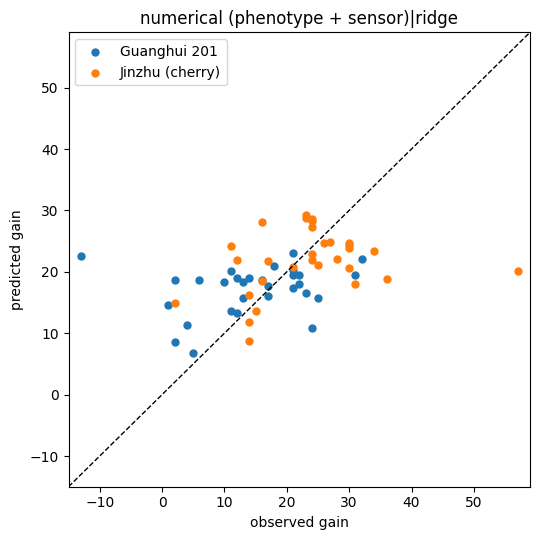

In [8]:
# Predicted vs observed for the main numerical model (leave-camera-out)
key = ('leave_camera_out', 'numerical (phenotype + sensor)|ridge')
pred = oof[key]
fig, ax = plt.subplots(figsize=(5.5, 5.5))
for v, idx in data.groupby('variety_name').groups.items():
    ax.scatter(y[idx], pred[idx], label=v, s=25)
lim = [min(y.min(), pred.min()) - 2, max(y.max(), pred.max()) + 2]
ax.plot(lim, lim, 'k--', lw=1); ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_xlabel('observed gain'); ax.set_ylabel('predicted gain'); ax.set_title(key[1]); ax.legend()
plt.tight_layout(); plt.show()

chosen alpha: 41.753189365604044


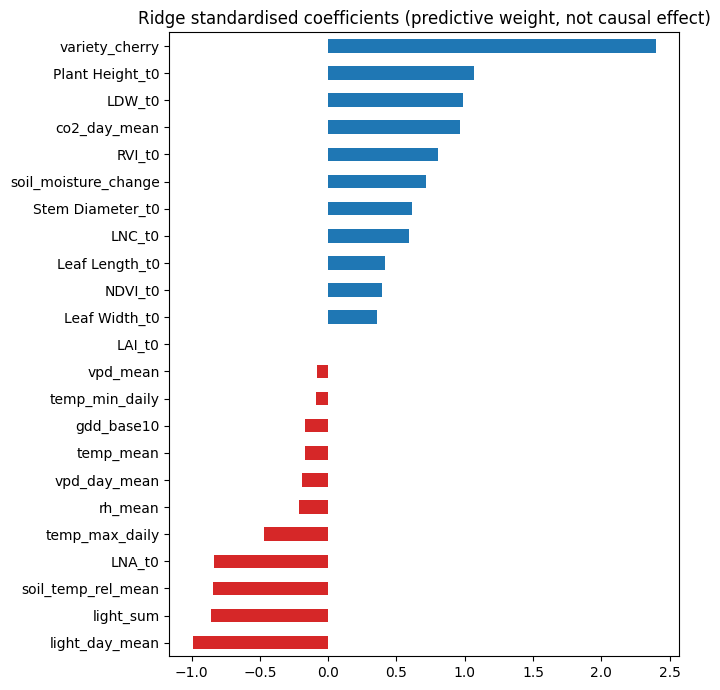

In [9]:
# Which features does the full Ridge model rely on? (fit on all data, standardised coefficients)
m = ridge().fit(data[PHENO_FEATS + SENSOR_FEATS], y)
coef = pd.Series(m[-1].coef_, index=PHENO_FEATS + SENSOR_FEATS).sort_values()
print('chosen alpha:', m[-1].alpha_)
fig, ax = plt.subplots(figsize=(7, 7))
coef.plot.barh(ax=ax, color=['C3' if v < 0 else 'C0' for v in coef])
ax.set_title('Ridge standardised coefficients (predictive weight, not causal effect)')
plt.tight_layout(); plt.show()

# Permutation importance with leave-camera-out folds would be stricter; the coefficients are a quick first look.

## 5. Largest errors (first look — full analysis comes after the image model)

In [10]:
data['pred_numerical'] = oof[('leave_camera_out', 'numerical (phenotype + sensor)|ridge')]
data['residual'] = data['y'] - data['pred_numerical']        # > 0 means the model UNDER-estimated growth
cols = ['plant', 'camera', 'sensor_zone', 'zone_is_proxy', 'treatment', 'variety_name',
        'Plant Height_t0', 'y', 'pred_numerical', 'residual']
print('Most UNDER-estimated (grew more than predicted):')
display(data.sort_values('residual', ascending=False)[cols].head(5).round(1))
print('Most OVER-estimated:')
display(data.sort_values('residual')[cols].head(5).round(1))
print('Mean absolute residual by camera:')
display(data.groupby('camera')['residual'].apply(lambda r: r.abs().mean()).round(1))

Most UNDER-estimated (grew more than predicted):


,plant,camera,sensor_zone,zone_is_proxy,treatment,variety_name,Plant Height_t0,y,pred_numerical,residual
35,L423,11411,GH_MEAN,True,T4,Jinzhu (cherry),192.0,57.0,20.2,36.8
34,L422,11411,GH_MEAN,True,T4,Jinzhu (cherry),189.0,36.0,18.9,17.1
55,L615,514614,T6,False,T6,Guanghui 201,200.0,24.0,10.9,13.1
33,L421,11411,GH_MEAN,True,T4,Jinzhu (cherry),194.0,31.0,18.0,13.0
25,CK12,11411,CK2,False,CK,Guanghui 201,242.0,31.0,19.5,11.5


Most OVER-estimated:


,plant,camera,sensor_zone,zone_is_proxy,treatment,variety_name,Plant Height_t0,y,pred_numerical,residual
2,L113,111211,T1,False,T1,Guanghui 201,218.0,-13.0,22.6,-35.6
50,L516,514614,T5,False,T5,Guanghui 201,149.0,2.0,18.7,-16.7
44,L613,511611,T6,False,T6,Guanghui 201,216.0,1.0,14.6,-13.6
47,L623,511611,T6,False,T6,Jinzhu (cherry),199.0,11.0,24.3,-13.3
46,L622,511611,T6,False,T6,Jinzhu (cherry),173.0,2.0,14.9,-12.9


Mean absolute residual by camera:


,residual
camera,
11411,9.3
111211,6.0
214311,4.8
511611,7.5
514614,7.4


## 6. Sensitivity check: all 108 hand-measured plants

The raw files contain 48 more plants (`R…` row + extra controls) measured on the same two days. They have no images in this
dataset, so they cannot enter the image/fusion comparison, but they tell us whether the **numerical** conclusions hold
with ~2× more plants. Groups for the strict CV are the raw-file camera positions (9 groups).

In [11]:
all_path = OUT_DIR / 'growth_measured_all.parquet'
if not all_path.exists():
    print('growth_measured_all.parquet not found — re-run notebook 01 (section 2b) to enable this check.')
else:
    raw_all = pd.read_parquet(all_path)
    r0 = raw_all[raw_all.date == T0].set_index('plant')
    r1 = raw_all[raw_all.date == T1].set_index('plant')
    big = r0[['side', 'treatment', 'variety', 'variety_name', 'camera_label', 'in_image_set']].copy()
    for c in PHENO:
        big[f'{c}_t0'] = r0[c]
    big['y'] = r1['Plant Height'] - r0['Plant Height']
    big['variety_cherry'] = (big['variety'] == 2).astype(int)

    # same zone rule as notebook 01: treatment -> its sensor zone, else greenhouse mean
    zones_with_sensor = set(zone_feats.sensor_zone) - {'GH_MEAN'}
    big['sensor_zone'] = big['treatment'].map(lambda t: 'CK2' if t == 'CK' else t)
    big['zone_is_proxy'] = ~big['sensor_zone'].isin(zones_with_sensor)
    big.loc[big.zone_is_proxy, 'sensor_zone'] = 'GH_MEAN'
    big = big.reset_index().merge(zone_feats, on='sensor_zone', how='left')
    print(len(big), 'plants |', big['in_image_set'].sum(), 'with images |', big['camera_label'].nunique(), 'camera groups')
    display(big.groupby('in_image_set')['y'].describe().round(1))

    yb = big['y'].values
    gb = big['camera_label'].values
    def oof_big(make_model, X, scheme):
        pred_sum, pred_n = np.zeros(len(yb)), np.zeros(len(yb))
        splits = (RepeatedKFold(n_splits=5, n_repeats=10, random_state=SEED).split(X) if scheme == 'kfold'
                  else LeaveOneGroupOut().split(X, yb, gb))
        for tr, te in splits:
            m = make_model().fit(X.iloc[tr], yb[tr])
            pred_sum[te] += m.predict(X.iloc[te]); pred_n[te] += 1
        return pred_sum / pred_n

    rows = []
    for scheme in ['kfold', 'leave_camera_out']:
        p = oof_big(lambda: DummyRegressor(), big[PHENO_FEATS], scheme)
        rows.append({'scheme': scheme, 'features': 'baseline (train mean)', 'model': 'mean',
                     'MAE': mean_absolute_error(yb, p), 'RMSE': mean_squared_error(yb, p) ** 0.5, 'R2': r2_score(yb, p)})
        for fs_name, cols in FEATURE_SETS.items():
            for model_name, mk in [('ridge', ridge), ('random_forest', forest)]:
                p = oof_big(mk, big[cols], scheme)
                rows.append({'scheme': scheme, 'features': fs_name, 'model': model_name,
                             'MAE': mean_absolute_error(yb, p), 'RMSE': mean_squared_error(yb, p) ** 0.5, 'R2': r2_score(yb, p)})
    res_big = pd.DataFrame(rows)
    comp = (res.assign(n_plants=60).merge(res_big.assign(n_plants=108), on=['scheme', 'features', 'model'],
                                          suffixes=('_60', '_108')))
    display(comp[['scheme', 'features', 'model', 'MAE_60', 'MAE_108', 'R2_60', 'R2_108']].round(3))
    res_big.to_csv(OUT_DIR / 'results_numerical_108.csv', index=False)

108 plants | 60 with images | 8 camera groups


,count,mean,std,min,25%,50%,75%,max
in_image_set,,,,,,,,
False,48.0,16.3,7.1,-1.0,13.0,18.0,20.0,30.0
True,60.0,18.9,10.8,-13.0,12.8,21.0,24.2,57.0


,scheme,features,model,MAE_60,MAE_108,R2_60,R2_108
0,kfold,baseline (train mean),mean,8.323,6.999,-0.026,-0.015
1,kfold,phenotype_only,ridge,7.499,6.693,0.102,0.044
2,kfold,phenotype_only,random_forest,7.419,6.948,0.115,0.000
3,kfold,sensor_only,ridge,7.824,6.915,0.009,-0.006
4,kfold,sensor_only,random_forest,7.933,6.953,0.037,-0.036
5,kfold,numerical (phenotype + sensor),ridge,6.950,6.490,0.208,0.078
6,kfold,numerical (phenotype + sensor),random_forest,6.643,6.886,0.246,0.015
7,leave_camera_out,baseline (train mean),mean,8.366,6.985,-0.053,-0.023
8,leave_camera_out,phenotype_only,ridge,7.521,6.628,0.069,0.046
9,leave_camera_out,phenotype_only,random_forest,7.630,7.042,0.053,-0.038


How to read it: if the ranking of feature sets is the same with 108 plants (phenotype + sensor > phenotype-only > baseline;
sensor-only weak), the conclusions from the 60-plant analysis are not an artefact of the small sample.
The extra plants share the same 6 sensor zones, so the sensor features still cannot separate plants within a zone.

In [12]:
# Save everything the next notebooks need
data.to_parquet(OUT_DIR / 'model_table_numerical.parquet', index=False)
res.to_csv(OUT_DIR / 'results_numerical.csv', index=False)
pd.Series({'T0': str(T0.date()), 'T1': str(T1.date())}).to_json(OUT_DIR / 'target_window.json')
print('Saved:', sorted(p.name for p in OUT_DIR.iterdir()))

Saved: ['bootstrap_comparison.csv', 'figures', 'growth_daily.parquet', 'growth_measured_all.parquet', 'image_features_plant.parquet', 'image_index.parquet', 'image_region_embeddings.npy', 'image_region_features.parquet', 'model_table_numerical.parquet', 'oof_image_leave_camera_out.parquet', 'plant_map.csv', 'predictions_per_plant.csv', 'results_final.csv', 'results_image.csv', 'results_numerical.csv', 'results_numerical_108.csv', 'sensors_long.parquet', 'sensors_zone_30min.parquet', 'target_window.json']
